# **Project Title**

# Relationship Between Screen Time, Physical Activity, and Health Problems in Children


# **Project Goal**


To analyze how daily screen time and physical activity relate to common health problems in school-age children (6-17 years), and to identify which children are at higher risk.



#  Objectives

1) Clean and prepare the dataset (remove duplicates, standardize categories, handle missing values and outliers).

2) Measure how common each health problem is: eye problems, sleeping issues, obesity, vitamin D deficiency and chronic constipation.

3) Examine whether higher screen time is linked to eye problems and sleeping issues.

4) Examine whether lower physical activity is linked to obesity and vitamin D deficiency.


5) Find no of health issues per child and report which factors matter most.

6) Summarize the findings with charts and practical recommendations, such as healthy screen-time limits.



# Dataset Information

| Attribute |	Value |
|---|---|
| Source | [Kaggle - child_health_lifestyle]|
| Records |	6064 students |
| Features |	14 columns |




# Importing libraries




In [1]:
# Data manipulation and analysis
import pandas as pd
import numpy as np
# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns
# Interactive visualizations
import plotly.express as px
import plotly.graph_objects as go

# Loading the Dataset

In [2]:
df=pd.read_excel("/content/MAIN_PROJECT-health_dataset_v7.xlsx")

In [3]:
# Checking the first few rows
df

,ID,Name,Gender,Age,School,City,Country,Physical_Activity_hours_per_day,Screen_Time_hours_per_day,Eye_Problems,Sleeping_Issues,Obesity,Vitamin_D_Deficiency,Chronic_Constipation
0,1,Emma Jones,Female,17,Franklin Elementary School,New York,UNITED STATES,0.0,2.0,yes,no,No,Y,no
1,2,Ava Johnson,Female,13,Jefferson Academy,Dallas,usa,2.0,1.0,No,no,N,YES,NO
2,3,William Harris,MALE,14,Jefferson Academy,Philadelphia,USA,2.0,2.0,NO,No,No,NO,No
3,4,Benjamin Moore,Male,16,Jefferson Academy,san diego,united states,2.0,3.0,no,NO,NO,no,no
4,5,Ella Johnson,female,12,Madison Middle School,austin,usa,2.0,3.0,yes,No,yes,No,yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6059,6055,Isabella Johnson,Female,10,Oak Ridge School,dallas,USA,1.0,2.0,No,no,NO,no,No
6060,6056,William Miller,Male,12,Oak Ridge School,san antonio,UNITED STATES,2.0,4.0,No,NO,No,no,N
6061,6057,Ava Jones,female,13,Madison Middle School,Los Angeles,united states,2.0,4.0,n,No,No,no,NO
6062,6058,Sophia Moore,f,11,Kennedy High School,chicago,united states,1.0,0.0,No,no,No,No,NO


# Initial Inspection

 Checking the the data types and structure of the dataset

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6064 entries, 0 to 6063
Data columns (total 14 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   ID                               6064 non-null   int64  
 1   Name                             6064 non-null   object 
 2   Gender                           6064 non-null   object 
 3   Age                              6064 non-null   int64  
 4   School                           6064 non-null   object 
 5   City                             6061 non-null   object 
 6   Country                          6056 non-null   object 
 7   Physical_Activity_hours_per_day  6059 non-null   float64
 8   Screen_Time_hours_per_day        6061 non-null   float64
 9   Eye_Problems                     6064 non-null   object 
 10  Sleeping_Issues                  6064 non-null   object 
 11  Obesity                          6064 non-null   object 
 12  Vitamin_D_Deficiency

In [5]:
df.head()

,ID,Name,Gender,Age,School,City,Country,Physical_Activity_hours_per_day,Screen_Time_hours_per_day,Eye_Problems,Sleeping_Issues,Obesity,Vitamin_D_Deficiency,Chronic_Constipation
0,1,Emma Jones,Female,17,Franklin Elementary School,New York,UNITED STATES,0.0,2.0,yes,no,No,Y,no
1,2,Ava Johnson,Female,13,Jefferson Academy,Dallas,usa,2.0,1.0,No,no,N,YES,NO
2,3,William Harris,MALE,14,Jefferson Academy,Philadelphia,USA,2.0,2.0,NO,No,No,NO,No
3,4,Benjamin Moore,Male,16,Jefferson Academy,san diego,united states,2.0,3.0,no,NO,NO,no,no
4,5,Ella Johnson,female,12,Madison Middle School,austin,usa,2.0,3.0,yes,No,yes,No,yes


In [6]:
df.tail()

,ID,Name,Gender,Age,School,City,Country,Physical_Activity_hours_per_day,Screen_Time_hours_per_day,Eye_Problems,Sleeping_Issues,Obesity,Vitamin_D_Deficiency,Chronic_Constipation
6059,6055,Isabella Johnson,Female,10,Oak Ridge School,dallas,USA,1.0,2.0,No,no,NO,no,No
6060,6056,William Miller,Male,12,Oak Ridge School,san antonio,UNITED STATES,2.0,4.0,No,NO,No,no,N
6061,6057,Ava Jones,female,13,Madison Middle School,Los Angeles,united states,2.0,4.0,n,No,No,no,NO
6062,6058,Sophia Moore,f,11,Kennedy High School,chicago,united states,1.0,0.0,No,no,No,No,NO
6063,6059,Michael Lewis,Male,8,Franklin Elementary School,new york,usa,0.0,2.0,No,No,N,No,No


In [7]:
df.dtypes

,0
ID,int64
Name,object
Gender,object
Age,int64
School,object
City,object
Country,object
Physical_Activity_hours_per_day,float64
Screen_Time_hours_per_day,float64
Eye_Problems,object


In [8]:
df.columns

Index(['ID', 'Name', 'Gender', 'Age', 'School', 'City', 'Country',
       'Physical_Activity_hours_per_day', 'Screen_Time_hours_per_day',
       'Eye_Problems', 'Sleeping_Issues', 'Obesity', 'Vitamin_D_Deficiency',
       'Chronic_Constipation'],
      dtype='object')

In [9]:
df.shape

(6064, 14)

In [10]:
df.describe()

,ID,Age,Physical_Activity_hours_per_day,Screen_Time_hours_per_day
count,6064.000000,6064.000000,6059.000000,6061.000000
mean,3030.389182,11.641326,1.313253,2.772315
std,1749.284282,5.076276,1.229483,1.277360
min,1.000000,6.000000,-3.000000,0.000000
25%,1515.750000,9.000000,1.000000,2.000000
50%,3030.500000,11.000000,1.000000,3.000000
75%,4546.250000,15.000000,2.000000,4.000000
max,6059.000000,199.000000,48.000000,5.000000


In [11]:
df.isnull().sum()

,0
ID,0
Name,0
Gender,0
Age,0
School,0
City,3
Country,8
Physical_Activity_hours_per_day,5
Screen_Time_hours_per_day,3
Eye_Problems,0


In [12]:
df.duplicated().sum()

np.int64(5)

# **DATA CLEANING**

Initial Data Inspection and Profiling: Examine the dataset's dimensions (rows and columns), schema, and overall structure to establish a clear understanding of the available features and summary statistics.

Missing Value Imputation and Treatment: Identify null, blank, or incomplete entries across all variables and address them through appropriate statistical imputation or record removal to maintain data completeness.

Duplicate Record Elimination: Detect and remove redundant entries to prevent data skew and ensure each observation is uniquely represented.

Data Type Standardization: Verify and convert each attribute to its appropriate data format (e.g., numerical, categorical, boolean, or datetime) to support accurate computation and visualization.

Data Normalization and Consistency Checks: Standardize irregular text formatting, resolve typographical errors, and unify categorical labels to ensure uniformity across the dataset.

Outlier Detection and Treatment: Identify extreme values or statistical anomalies using analytical distributions and visual diagnostics, addressing them as needed to prevent distortion in downstream analysis.

Post-Cleaning Data Validation: Conduct a final quality assurance review to verify that the processed dataset is accurate, consistent, and fully prepared for exploratory data analysis (EDA) and modeling.

#  Showing all duplicate records


In [13]:
print(df[df.duplicated(keep=False)].sort_values("ID"))

        ID             Name  Gender  Age                    School  \
575    576  Benjamin Martin       M   12          Oak Ridge School   
1318   576  Benjamin Martin       M   12          Oak Ridge School   
2374  2370      Logan Jones    Male   16     Roosevelt High School   
1549  2370      Logan Jones    Male   16     Roosevelt High School   
4660  4656  Amelia Williams       f    7  Washington Middle School   
642   4656  Amelia Williams       f    7  Washington Middle School   
1081  4882      Jackson Lee    male   15          Oak Ridge School   
4886  4882      Jackson Lee    male   15          Oak Ridge School   
1902  5026     Emily Harris  Female   15     Madison Middle School   
5030  5026     Emily Harris  Female   15     Madison Middle School   

              City        Country  Physical_Activity_hours_per_day  \
575    san antonio            USA                              1.0   
1318   san antonio            USA                              1.0   
2374  philadelphia 

In [14]:
 # Checking the number of duplicate rows
 print("no of duplicated rows:",df.duplicated().sum())




no of duplicated rows: 5


# Removing Duplicates

In [15]:
# Removing duplicate rows
df=df.drop_duplicates()


#  Checking the number of duplicate rows
print("No of duplicated rows:",df.duplicated().sum())

# Checking the IDs are unique
df['ID'].is_unique




No of duplicated rows: 0


True

# Checking the number of missing values in each column

In [16]:
# Checking the number of missing values in each column
df.isnull().sum()

,0
ID,0
Name,0
Gender,0
Age,0
School,0
City,3
Country,8
Physical_Activity_hours_per_day,5
Screen_Time_hours_per_day,3
Eye_Problems,0


# Handling Invalid Values

In [17]:
# Checking for invalid values in the Physical_Activity_hours_per_day  column
df['Physical_Activity_hours_per_day'].unique()



# Replacing invalid Physical Activity Hours with NaN
df.loc[
    (df['Physical_Activity_hours_per_day'] < 0) |
    (df['Physical_Activity_hours_per_day'] > 20),
    'Physical_Activity_hours_per_day'
] = np.nan

# Checking missing values after replacing invalid values
print("No of missing values in the Physical_Activity_hours_per_day column:",df['Physical_Activity_hours_per_day'].isnull().sum())



No of missing values in the Physical_Activity_hours_per_day column: 13


In [18]:
# Checking for invalid values in the Age column
print("unique ages",df['Age'].unique())

# Counting rows where age is greater than 17 and less than 6
print("no of outliers",(df['Age'] > 17).sum() + (df['Age'] < 6).sum())

# Dropping rows where Age is greater than 17 and less than 6
df = df.drop(df[(df['Age'] > 17) | (df['Age'] < 6)].index)

# Checking the number of rows where Age is greater than 17 and less than 6
print("no of outliers",(df['Age'] > 17).sum() + (df['Age'] < 6).sum())

# Checking the number of missing values in the Age column
print("No of missing values in the Age column:",df['Age'].isnull().sum())






unique ages [ 17  13  14  16  12  15   8   6   9  11   7  10 199 150 112 105 120]
no of outliers 5
no of outliers 0
No of missing values in the Age column: 0


# Imputing Missing values

In [19]:
# Imputing missing values in the City column with Unknown
df.loc[:,'City']=df['City'].fillna('Unknown')


# Checking the number of missing values in the City column
print("The number of missing values in the City column:",df['City'].isnull().sum())

The number of missing values in the City column: 0


In [20]:
# Imputing missing Country values with "USA" based on the dataset context
df.loc[:,'Country']=df['Country'].fillna("USA")


# Checking the number of missing values in the Country column
print("The number of missing values in the Country column:",df['Country'].isnull().sum())

The number of missing values in the Country column: 0


In [21]:
# Imputing missing values in the Physical_Activity_hours_per_day  with the median
df.loc[:,'Physical_Activity_hours_per_day']=df['Physical_Activity_hours_per_day'].fillna(df['Physical_Activity_hours_per_day'].median())


# Checking the number of missing values in the Physical_Activity_hours_per_day column
print("The number of missing values in the Physical_Activity_hours_per_day column:",df['Physical_Activity_hours_per_day'].isnull().sum())


The number of missing values in the Physical_Activity_hours_per_day column: 0


In [22]:
# Imputing missing values in the Screen_Time_hours_per_day with the median
df.loc[:,'Screen_Time_hours_per_day']=df['Screen_Time_hours_per_day'].fillna(df['Screen_Time_hours_per_day'].median())



# Checking the number of missing values in the Screen_Time_hours_per_day column
print("The number of missing values in the Screen_Time_hours_per_day column:",df['Screen_Time_hours_per_day'].isnull().sum())


The number of missing values in the Screen_Time_hours_per_day column: 0


### Standardizing Inconsistencies

In [23]:
# Checking for inconsistent values in the Gender column
df['Gender'].unique()


# Standardizing inconsistent values in the Gender column
df['Gender']=df['Gender'].replace({

     'MALE':'Male',
     'female':'Female',
     'male':'Male',
     'M':'Male',
     'm':'Male',
     'f':'Female',
     'F':'Female',
     'FEMALE':'Female'
     })

# # Checking standardized Gender values

df['Gender'].unique()


array(['Female', 'Male'], dtype=object)

In [24]:
# Checking for inconsistent values in the City column
df['City'].unique()

# Standardizing inconsistent values in the City column
df['City']=df['City'].str.title()

# Checking standardized City values
df['City'].unique()



array(['New York', 'Dallas', 'Philadelphia', 'San Diego', 'Austin',
       'San Antonio', 'Seattle', 'Phoenix', 'Los Angeles', 'Boston',
       'Houston', 'Denver', 'Chicago', 'Atlanta', 'Miami', 'Unknown'],
      dtype=object)

In [25]:
# Checking for inconsistent values in the Country column
df['Country'].unique()


# Standardizing inconsistent values in the Country column
df['Country']=df['Country'].replace({

   'UNITED STATES': 'USA',
   'usa':'USA',
   'united states':'USA'

})

# Checking standardized City values
df['Country'].unique()

array(['USA'], dtype=object)

In [26]:
# Checking for inconsistent values in Eye_Problems,the Sleeping_Issues, Obesity, Vitamin_D_Deficiency and Chronic_Constipation columns
columns=['Eye_Problems','Sleeping_Issues','Obesity','Vitamin_D_Deficiency','Chronic_Constipation']
for column in columns:
  print(column,":",df[column].unique())


# Standardizing inconsistent values in all five columns

for column in columns:

  df[column]=df[column].replace({

      'yes':'Yes',

      'NO':'No',

      'no':'No',

      'n':'No',

      'y':'Yes',

      'N':'No',

      'YES':'Yes',

      'Y':'Yes'

})

# Checking standardized values in all five columns
for column in columns:
  print(column,":",df[column].unique())


Eye_Problems : ['yes' 'No' 'NO' 'no' 'n' 'y' 'N' 'YES' 'Yes' 'Y']
Sleeping_Issues : ['no' 'No' 'NO' 'Yes' 'yes' 'y' 'YES' 'N' 'n' 'Y']
Obesity : ['No' 'N' 'NO' 'yes' 'Y' 'n' 'no' 'Yes' 'YES' 'y']
Vitamin_D_Deficiency : ['Y' 'YES' 'NO' 'no' 'No' 'N' 'n' 'yes' 'Yes' 'y']
Chronic_Constipation : ['no' 'NO' 'No' 'yes' 'n' 'N' 'YES' 'Yes' 'y' 'Y']
Eye_Problems : ['Yes' 'No']
Sleeping_Issues : ['No' 'Yes']
Obesity : ['No' 'Yes']
Vitamin_D_Deficiency : ['Yes' 'No']
Chronic_Constipation : ['No' 'Yes']


# Exploratory Data Analysis (EDA)


     Exploratory Data Analysis (EDA) is used to understand the children health dataset and explore relationships between  screen time and physical activity and  common health problems in  children (6-17 years), and to identify which children are at higher risk.

In [27]:
# Understanding Individual Columns & Data Types
df.info()


<class 'pandas.core.frame.DataFrame'>
Index: 6054 entries, 0 to 6063
Data columns (total 14 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   ID                               6054 non-null   int64  
 1   Name                             6054 non-null   object 
 2   Gender                           6054 non-null   object 
 3   Age                              6054 non-null   int64  
 4   School                           6054 non-null   object 
 5   City                             6054 non-null   object 
 6   Country                          6054 non-null   object 
 7   Physical_Activity_hours_per_day  6054 non-null   float64
 8   Screen_Time_hours_per_day        6054 non-null   float64
 9   Eye_Problems                     6054 non-null   object 
 10  Sleeping_Issues                  6054 non-null   object 
 11  Obesity                          6054 non-null   object 
 12  Vitamin_D_Deficiency     

The dataset contains 6,064 rows and 14 columns, categorized into two main types:

Numerical Columns (4): ID, Age, Physical_Activity_hours_per_day, and Screen_Time_hours_per_day.
Categorical/Text Columns (10): Name, Gender, School, City, Country, and five health status indicators (Eye_Problems, Sleeping_Issues, Obesity, Vitamin_D_Deficiency, and Chronic_Constipation).

# Checking missing values


In [28]:
# Checking missing values
df.isnull().sum()

,0
ID,0
Name,0
Gender,0
Age,0
School,0
City,0
Country,0
Physical_Activity_hours_per_day,0
Screen_Time_hours_per_day,0
Eye_Problems,0


# Analysis of Numerical Data

In [29]:
 # Analysis of Numerical Data
 # Evaluating the mean,median,minimum,maximum and standard deviation for the core numerical features:
 numerical_columns=['Age','Physical_Activity_hours_per_day','Screen_Time_hours_per_day']

print("Mean:")
print(df[numerical_columns].mean())

print("\nMedian:")
print(df[numerical_columns].median())

print("\nMinimum:")
print(df[numerical_columns].min())

print("\nMaximum:")
print(df[numerical_columns].max())

print("\nStandard Deviation:")
print(df[numerical_columns].std())





Mean:
Age                                11.536505
Physical_Activity_hours_per_day     1.288570
Screen_Time_hours_per_day           2.772217
dtype: float64

Median:
Age                                11.0
Physical_Activity_hours_per_day     1.0
Screen_Time_hours_per_day           3.0
dtype: float64

Minimum:
Age                                6.0
Physical_Activity_hours_per_day    0.0
Screen_Time_hours_per_day          0.0
dtype: float64

Maximum:
Age                                17.0
Physical_Activity_hours_per_day     3.0
Screen_Time_hours_per_day           5.0
dtype: float64

Standard Deviation:
Age                                3.432804
Physical_Activity_hours_per_day    0.806678
Screen_Time_hours_per_day          1.277394
dtype: float64


In [30]:

# Checking the number of missing values in the numerical  columns
numerical_columns=['ID','Age','Physical_Activity_hours_per_day','Screen_Time_hours_per_day']
for column in numerical_columns:
  print(column,":",df[column].isnull().sum())


ID : 0
Age : 0
Physical_Activity_hours_per_day : 0
Screen_Time_hours_per_day : 0


In [31]:
df.describe()

,ID,Age,Physical_Activity_hours_per_day,Screen_Time_hours_per_day
count,6054.000000,6054.000000,6054.000000,6054.000000
mean,3030.070202,11.536505,1.288570,2.772217
std,1749.004671,3.432804,0.806678,1.277394
min,1.000000,6.000000,0.000000,0.000000
25%,1516.250000,9.000000,1.000000,2.000000
50%,3030.500000,11.000000,1.000000,3.000000
75%,4543.750000,15.000000,2.000000,4.000000
max,6059.000000,17.000000,3.000000,5.000000


# Findings after numerical analysis



 Average age :11

 Average physical activity hours per day:1


 Average screen time hours per day: 3

 school children of ages 6 to 17



  0–3 hours of physical activity

  0–5 hours of screen time

  no outliers in the  data

  no missing values

# Groupby and average analysis
*   Comparing average values across different groups.
*   Calculating the average physical activity time and screentime for each school,city and age  



## Average Screen Time by School

In [32]:
print("Average Screen Time Hours Per Day by School:")
print(df.groupby('School')['Screen_Time_hours_per_day'].mean().sort_values(ascending=False))

Average Screen Time Hours Per Day by School:
School
Roosevelt High School         2.824934
Oak Ridge School              2.819892
Kennedy High School           2.817272
Washington Middle School      2.806268
Madison Middle School         2.774809
Lincoln Elementary School     2.762689
Jefferson Academy             2.693082
Franklin Elementary School    2.681879
Name: Screen_Time_hours_per_day, dtype: float64


# Average Screen Time by City

In [33]:
print("Average Screen Time Hours Per Day by City:")
print(df.groupby('City')['Screen_Time_hours_per_day'].mean().sort_values(ascending=False))

Average Screen Time Hours Per Day by City:
City
Seattle         2.885442
Atlanta         2.871537
San Diego       2.858228
Boston          2.844828
Dallas          2.832579
New York        2.827493
San Antonio     2.811138
Miami           2.799555
Austin          2.773585
Houston         2.766332
Phoenix         2.704762
Los Angeles     2.697548
Unknown         2.666667
Denver          2.660714
Philadelphia    2.627792
Chicago         2.610294
Name: Screen_Time_hours_per_day, dtype: float64


# Average Physical Activity by School

In [34]:
print("Average Physical activity hours per day by School:")
print(df.groupby('School')['Physical_Activity_hours_per_day'].mean().sort_values(ascending=False))

Average Physical activity hours per day by School:
School
Oak Ridge School              1.349462
Jefferson Academy             1.306918
Lincoln Elementary School     1.293553
Roosevelt High School         1.293103
Madison Middle School         1.290076
Franklin Elementary School    1.287248
Washington Middle School      1.250712
Kennedy High School           1.237797
Name: Physical_Activity_hours_per_day, dtype: float64


# Average Physical Activity by City

In [35]:
print("Average Physical activity hours per day by City:")
print(df.groupby('City')['Physical_Activity_hours_per_day'].mean().sort_values(ascending=False))

Average Physical activity hours per day by City:
City
Unknown         2.000000
Los Angeles     1.389646
Phoenix         1.340476
Boston          1.330049
Philadelphia    1.315136
Atlanta         1.312343
Chicago         1.308824
San Antonio     1.297821
New York        1.291105
Denver          1.288265
Dallas          1.282805
Austin          1.272237
Miami           1.251670
Seattle         1.224344
San Diego       1.222785
Houston         1.206030
Name: Physical_Activity_hours_per_day, dtype: float64


# Average Physical Activity by Age

In [36]:
print("Average Physical activity hours per day by Age:")
print(df.groupby('Age')['Physical_Activity_hours_per_day'].mean().sort_values(ascending=False))

Average Physical activity hours per day by Age:
Age
15    1.328302
14    1.327553
13    1.325956
11    1.301961
6     1.297357
10    1.297087
17    1.290389
9     1.289179
12    1.284464
16    1.267176
7     1.251969
8     1.201942
Name: Physical_Activity_hours_per_day, dtype: float64


# Average Screen time by Age

In [37]:
print("Average Screen time hours per day by Age:")
print(df.groupby('Age')['Screen_Time_hours_per_day'].mean().sort_values(ascending=False))

Average Screen time hours per day by Age:
Age
17    3.014315
16    2.988550
15    2.952830
14    2.884393
13    2.804829
11    2.788235
12    2.783370
9     2.722015
8     2.646602
10    2.601942
7     2.539370
6     2.513216
Name: Screen_Time_hours_per_day, dtype: float64


# Analysis of Categorical Data

To Understand the frequency of categories in columns such as Name, Gender, School, City, Country, and five health status indicators (Eye_Problems, Sleeping_Issues, Obesity, Vitamin_D_Deficiency, and Chronic_Constipation).
Count the number of records belonging to each category.

In [38]:
categorical_cols = ['Name', 'Gender', 'School', 'City', 'Country', 'Eye_Problems', 'Sleeping_Issues', 'Obesity', 'Vitamin_D_Deficiency', 'Chronic_Constipation']



for col in categorical_cols:
    if col in df.columns:
        print("\nCategory Analysis:", col)
        print(df[col].value_counts(dropna=False))


Category Analysis: Name
Name
Logan Taylor       28
Olivia Brown       23
Liam Martin        23
William Clark      23
Logan Jones        22
                   ..
Madison Martin      5
Benjamin Harris     5
Henry Smith         4
Grace Thomas        3
Emily Clark         2
Name: count, Length: 500, dtype: int64

Category Analysis: Gender
Gender
Male      3200
Female    2854
Name: count, dtype: int64

Category Analysis: School
School
Kennedy High School           799
Jefferson Academy             795
Madison Middle School         786
Roosevelt High School         754
Franklin Elementary School    745
Oak Ridge School              744
Lincoln Elementary School     729
Washington Middle School      702
Name: count, dtype: int64

Category Analysis: City
City
Miami           449
Dallas          442
Phoenix         420
Seattle         419
San Antonio     413
Chicago         408
Boston          406
Philadelphia    403
Houston         398
Atlanta         397
San Diego       395
Denver          3

# KEY FINDINGS:

Name: 500 unique student names, with Logan Taylor being the most frequent (28 times).

Gender: Nearly even split between Male (3,200) and Female (2,854).

School: Led by Kennedy High School (799) and Jefferson Academy (795).

City: Concentrated across major cities, highest in Miami (449) and Dallas (442).

Country: Entirely based in the USA (6,054).

Health Indicators: The vast majority report "No" across all health conditions (Eye Problems: 1,373 Yes; Sleeping Issues: 1,086 Yes; Obesity: 1,035 Yes; Vitamin D Deficiency: 1,348 Yes; Chronic Constipation: 421 Yes).


# Categorical Frequency & Dominant Mode Identification

* **Objective:** To determine the most representative or frequently occurring category within each categorical attribute.
* **Methodology:** Utilizing the statistical mode (`.mode()`) to isolate the primary value, alongside absolute frequency counts (`.value_counts()`) to quantify its prevalence across the dataset.

In [39]:
categorical_cols = ['Name', 'Gender', 'School', 'City', 'Country', 'Eye_Problems', 'Sleeping_Issues', 'Obesity', 'Vitamin_D_Deficiency', 'Chronic_Constipation']


for col in categorical_cols:
    if col in df.columns:
        print("\nMost Common Category:", col)
        print("Category:", df[col].mode().tolist())
        print("Frequency:")
        print(df[col].value_counts().head(10))


Most Common Category: Name
Category: ['Logan Taylor']
Frequency:
Name
Logan Taylor      28
Olivia Brown      23
Liam Martin       23
William Clark     23
Logan Jones       22
Madison Smith     22
Amelia Davis      21
William Davis     20
Logan Miller      19
Jackson Harris    19
Name: count, dtype: int64

Most Common Category: Gender
Category: ['Male']
Frequency:
Gender
Male      3200
Female    2854
Name: count, dtype: int64

Most Common Category: School
Category: ['Kennedy High School']
Frequency:
School
Kennedy High School           799
Jefferson Academy             795
Madison Middle School         786
Roosevelt High School         754
Franklin Elementary School    745
Oak Ridge School              744
Lincoln Elementary School     729
Washington Middle School      702
Name: count, dtype: int64

Most Common Category: City
Category: ['Miami']
Frequency:
City
Miami           449
Dallas          442
Phoenix         420
Seattle         419
San Antonio     413
Chicago         408
Boston

# KEY FINDINGS:
Name: Logan Taylor (28)

Gender: Male (3,200)

School: Kennedy High School (799)

City: Miami (449)

Country: USA (6,054)

Health Indicators: Mostly "No" across all conditions (Eye Problems: 4,681 | Sleeping Issues: 4,968 | Obesity: 5,019 | Vitamin D Deficiency: 4,706 | Chronic Constipation: 5,633).

In [40]:
# Analysis of Categorical Data
df.describe(include='object')

,Name,Gender,School,City,Country,Eye_Problems,Sleeping_Issues,Obesity,Vitamin_D_Deficiency,Chronic_Constipation
count,6054,6054,6054,6054,6054,6054,6054,6054,6054,6054
unique,500,2,8,16,1,2,2,2,2,2
top,Logan Taylor,Male,Kennedy High School,Miami,USA,No,No,No,No,No
freq,28,3200,799,449,6054,4681,4968,5019,4706,5633


# KEY FINDINGS:
Gender Distribution: Total 2 categories.Male and Female.

School Distribution: Total 8 schools.

City Distribution: Spans across 16 major cities.

Country Distribution: USA.

Health Status Indicators: (Yes / No)

# Percentage Analysis

* **Objective:** To determine the relative percentage share of records within each categorical attribute.
* **Analytical Purpose:** Facilitates comparative evaluations across demographic segments (such as gender distribution) and categorical health problems groupings.
* **Mathematical Formula:**  Percentage = (Category count / Total records) × 100


In [41]:
percentage_cols = ['Gender','Eye_Problems', 'Sleeping_Issues', 'Obesity', 'Vitamin_D_Deficiency', 'Chronic_Constipation']

for col in percentage_cols:
    print(f"\nPercentage distribution of {col}:")
    print(((df[col].value_counts(normalize=True) * 100).round(2).astype(str) + ' %'))


Percentage distribution of Gender:
Gender
Male      52.86 %
Female    47.14 %
Name: proportion, dtype: object

Percentage distribution of Eye_Problems:
Eye_Problems
No     77.32 %
Yes    22.68 %
Name: proportion, dtype: object

Percentage distribution of Sleeping_Issues:
Sleeping_Issues
No     82.06 %
Yes    17.94 %
Name: proportion, dtype: object

Percentage distribution of Obesity:
Obesity
No     82.9 %
Yes    17.1 %
Name: proportion, dtype: object

Percentage distribution of Vitamin_D_Deficiency:
Vitamin_D_Deficiency
No     77.73 %
Yes    22.27 %
Name: proportion, dtype: object

Percentage distribution of Chronic_Constipation:
Chronic_Constipation
No     93.05 %
Yes     6.95 %
Name: proportion, dtype: object


# KEY FINDINGS

The relative percentage share of records across demographic and health attributes

### **1. Demographic Distribution**
* **Gender Breakdown:**
  * **Male:** **52.87%**
  * **Female:** **47.13%**

---

### **2. Health Status & Condition Prevalence**
* **Eye Problems:**
  * **No:** **77.33%**
  * **Yes:** **22.67%**

* **Sleeping Issues:**
  * **No:** **82.06%**
  * **Yes:** **17.94%**

* **Obesity:**
  * **No:** **82.92%**
  * **Yes:** **17.08%**

* **Vitamin D Deficiency:**
  * **No:** **77.72%**
  * **Yes:** **22.28%**

* **Chronic Constipation:**
  * **No:** **93.06%**
  * **Yes:** **6.94%**


# **Data Visualization**

*  Turning raw data into charts and graphs to easily spot trends, patterns, and outliers.


       
       

Univariate analysis is used to study one column (variable) at a time.

Bivariate analysis is the study of two columns (variables) at the same time to see if there is a relationship, connection, or pattern between them.      

# 1) Histogram(Univariate Analysis)

A histogram is used to visualize the distribution of numerical variables(Age,Physical_Activity_hours_per_day,Screen_Time_hours_per_day)

It helps to understand how the values are distributed across different ranges.

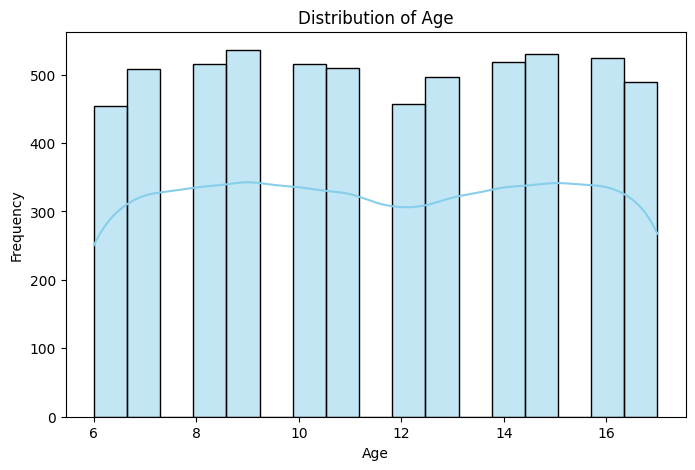

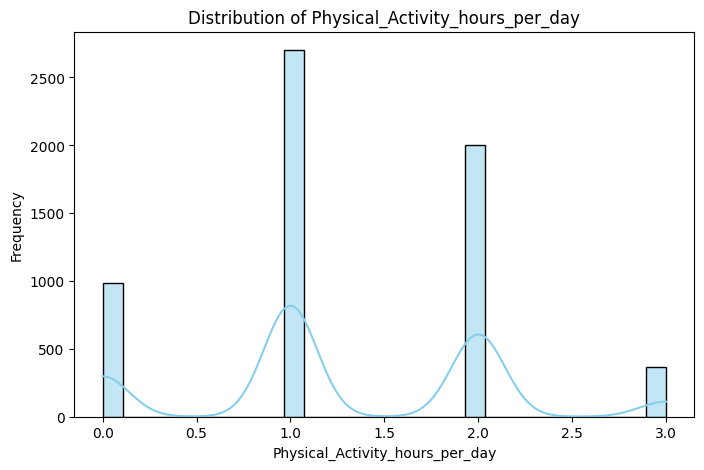

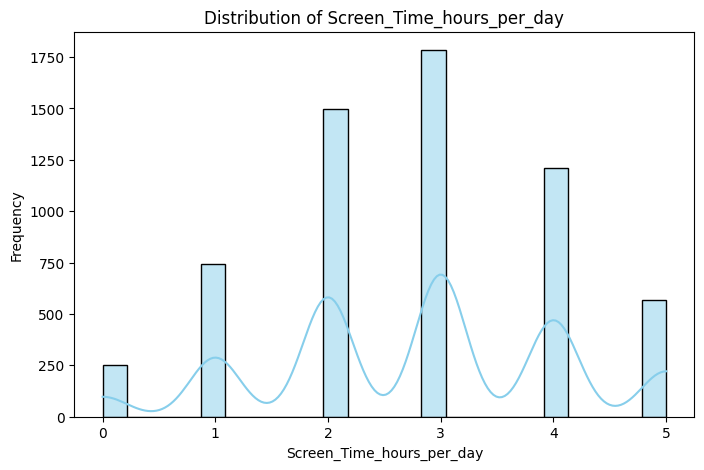

In [42]:
numerical_columns = ['Age','Physical_Activity_hours_per_day','Screen_Time_hours_per_day']

for column in numerical_columns:
    plt.figure(figsize=(8, 5))

    sns.histplot(
        data=df,
        x=column,
        kde=True,
        color='skyblue'
    )

    plt.title(f'Distribution of {column}')
    plt.xlabel(column)
    plt.ylabel('Frequency')
    plt.show()




# KEY FINDINGS:
1)Every single age group has roughly the same number of students.

2)Most students are active for 1 to 2 hours a day, with 1 hour being the most common. Only a small number of students do 3 hours of activity, while around 1,000 students do none at all.

3)Most students use screens for 2 to 4 hours a day, with 3 hours being the most common. Very few students spend 5 hours on screens, and few has 0 hours of screen time.


# 2) Piechart(Univariate Analysis)

# Demographic Analysis: Gender Distribution
This section evaluates the demographic breakdown of the student population to understand the gender distribution within the dataset.

Objective: To compare the proportional representation of different gender categories among the participants.
Variable Analyzed: Gender (Male and Female).

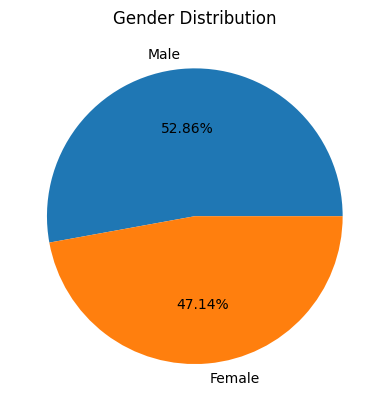

In [43]:


df['Gender'].value_counts().plot(
    kind='pie', autopct='%1.2f%%'
)
plt.title('Gender Distribution')
plt.ylabel('')
plt.show()

# KEY FINDINGS:



* **Male Students:** Comprise **52.9%** of the population.
* **Female Students:** Comprise **47.1%** of the population.


The gender split is relatively even, showing a slight majority of male participants. This balanced distribution ensures that subsequent analyses regarding lifestyle habits, screen time, and health problems are not heavily skewed by gender bias.

# 3)Line chart(Bivariate Analysis)

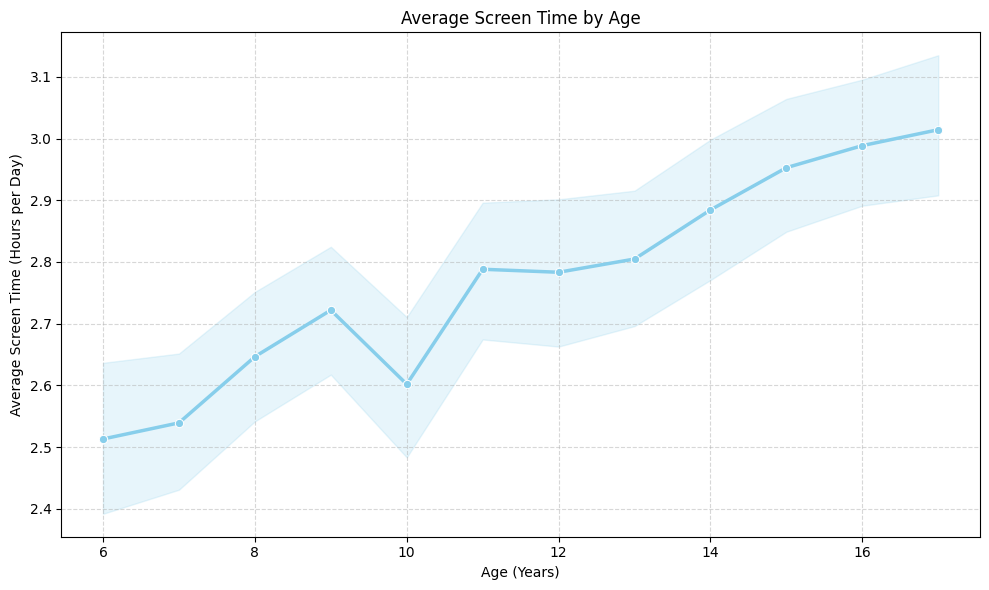

In [44]:
plt.figure(figsize=(10, 6))

sns.lineplot(
    data=df,
    x='Age',
    y='Screen_Time_hours_per_day',
    estimator='mean',
    marker='o',
    color='skyblue',
    linewidth=2.5
)

plt.title('Average Screen Time by Age')
plt.xlabel('Age (Years)')
plt.ylabel('Average Screen Time (Hours per Day)')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


# KEY FINDINGS:
Overall increasing trend: Average screen time increases from approximately 2.51 hours at younger ages to 3.01 hours at older ages.
Age-related increase: Older children generally have higher average screen time than younger children.

# 4) Bar Chart(Univariate Analysis)
Bar chart is used for the comparison of categorical data.This
bar Chart shows number of students by school.



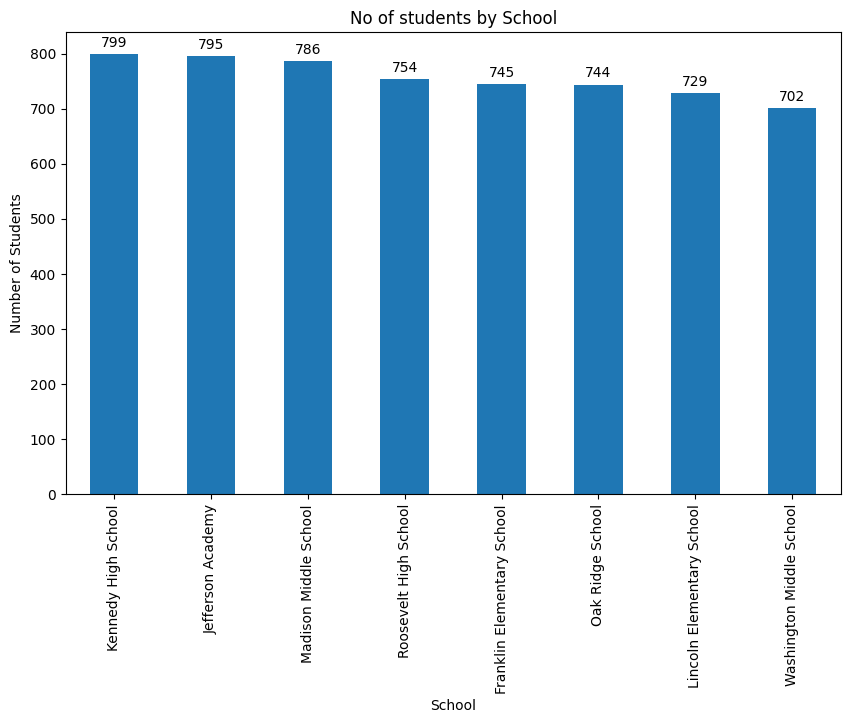

In [45]:


plt.figure(figsize=(10, 6))

# 1. Assign the plot to a variable called 'ax'
ax = df['School'].value_counts().plot(kind='bar')

# 2. Add the exact numbers on top of each bar
ax.bar_label(ax.containers[0], padding=3)

plt.title('No of students by School')
plt.xlabel('School')
plt.ylabel('Number of Students')
plt.xticks(rotation=90)
plt.show()

# KEY FINDINGS:

Total 8 schools present in the data set.

Distribution is almost uniform with 702 to 799 students per school.

# 5) Box Plot (Univariate Analysis)
    Age Analysis
Box Plot shows the spread, median, and potential outliers in the age.



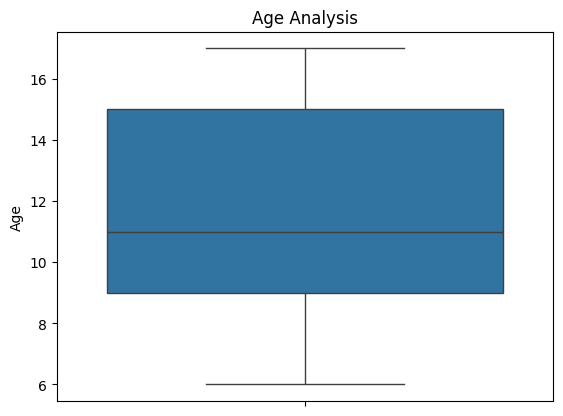

In [46]:
sns.boxplot(y=df['Age'])

plt.title('Age Analysis')
plt.ylabel('Age')
plt.show()

# KEY FINDINGS:
 The box represents the middle 50% of age, the central line represents the median, and there is no  potential outliers.


# 6)Scatter Plot(Bivariate Analysis)

 Scatter Plot is used  to identify the direction and strength of the relationship between two numerical variables.This
scatter Plot shows the relationship between age and physical activity hours per day.



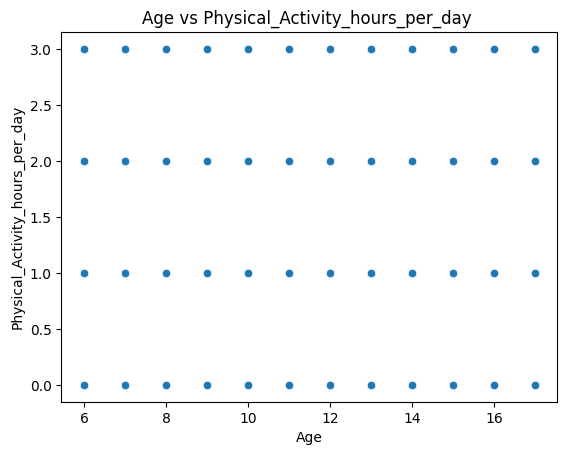

In [47]:
sns.scatterplot(
    data=df,
    x='Age',
    y='Physical_Activity_hours_per_day'

)

plt.title('Age vs Physical_Activity_hours_per_day ')
plt.xlabel('Age')
plt.ylabel('Physical_Activity_hours_per_day')
plt.show()

# KEY FINDINGS:

It shows no correlation.physical activity is independend of age.All ages show same 4 levels of activity.

# **7)Bar Chart**(Univariate Analysis):
This barchart shows percentages and counts for eye problems, sleeping issues, obesity, vitamin D deficiency, and chronic constipation

# Health Problem Prevalence Analysis

         Health_Problem  Count  Prevalence_Percentage
0          Eye_Problems   1373                  22.68
1       Sleeping_Issues   1086                  17.94
2               Obesity   1035                  17.10
3  Vitamin_D_Deficiency   1348                  22.27
4  Chronic_Constipation    421                   6.95


/tmp/ipykernel_4031/4242613344.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_prevalence, x='Health_Problem', y='Prevalence_Percentage', palette='viridis')


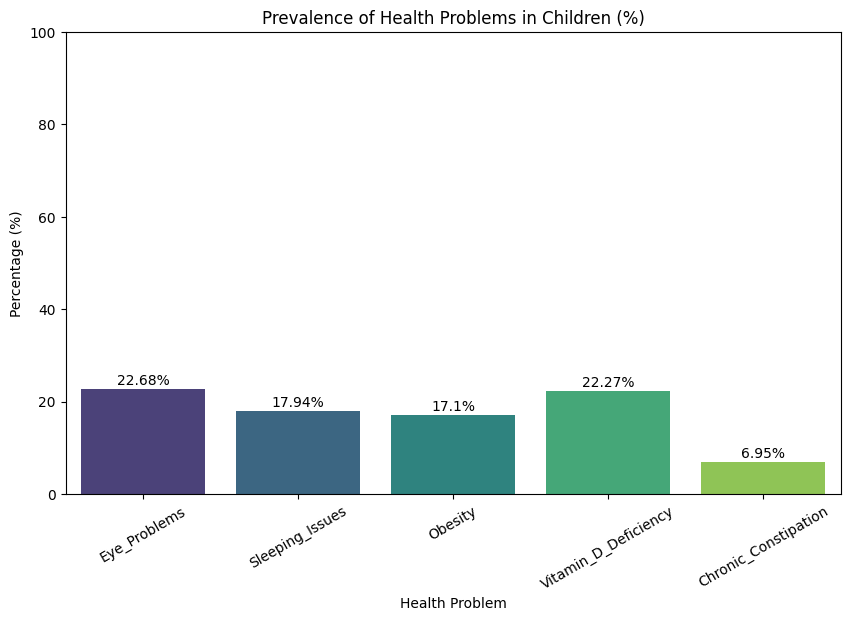

In [48]:
# Measuring percentages and counts for eye problems, sleeping issues, obesity, vitamin D deficiency, and chronic constipation
# Calculating the percentage and count of each health problem
health_columns = ['Eye_Problems', 'Sleeping_Issues', 'Obesity', 'Vitamin_D_Deficiency', 'Chronic_Constipation']

prevalence_summary = []
for col in health_columns:
    # Count 'Yes' values
    count_yes = (df[col] == 'Yes').sum()
    percentage = (count_yes / len(df)) * 100
    prevalence_summary.append({'Health_Problem': col, 'Count': count_yes, 'Prevalence_Percentage': round(percentage, 2)})

df_prevalence = pd.DataFrame(prevalence_summary)
print(df_prevalence)

# Plotting the prevalence
plt.figure(figsize=(10, 6))
sns.barplot(data=df_prevalence, x='Health_Problem', y='Prevalence_Percentage', palette='viridis')
plt.title('Prevalence of Health Problems in Children (%)')
plt.xlabel('Health Problem')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=30)
plt.ylim(0, 100)
for index, row in df_prevalence.iterrows():
    plt.text(index, row['Prevalence_Percentage'] + 1, f"{row['Prevalence_Percentage']}%", color='black', ha="center")
plt.show()

# KEY FINDINGS

After cleaning the dataset and analyzing the distribution of the five key health conditions among school-age children (6-17 years), the prevalence summary reveals the following:

* **Most Common Issues:** Eye Problems affects the largest share of children in this dataset at approximately 22.68 %.
* **Secondary Concerns:** Conditions such as Vitamin D Deficiency also show significant representation, impacting around 22.27 % of the surveyed students.
* **Other Notable Conditions:** Sleeping Issues affect 17.94 % and Obesity affects 17.10 % of the children.
* **Least Common Issue:** Chronic Constipation represents the smallest share at 6.95 %.

## 8) HEAT MAP(Bivariate Analysis)

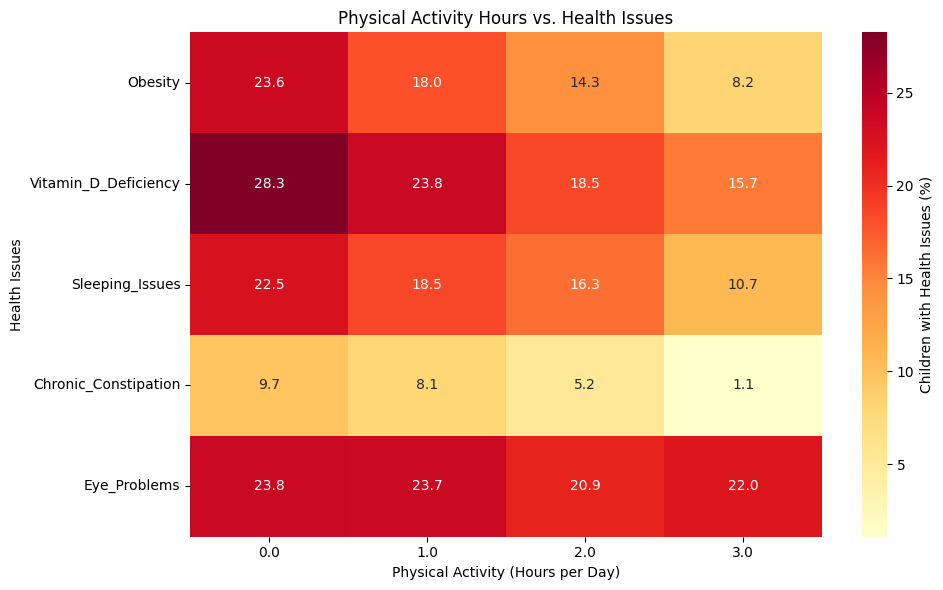

In [49]:


# Health issues to analyze
health_columns = [
    'Obesity',
    'Vitamin_D_Deficiency',
    'Sleeping_Issues',
    'Chronic_Constipation',
    'Eye_Problems'
]

# Select children with 0, 1, 2, or 3 hours of physical activity
activity_df = df[
    df['Physical_Activity_hours_per_day'].isin([0, 1, 2, 3])
].copy()

# Calculate the percentage with each health issue
results = {}

for col in health_columns:
    results[col] = (
        activity_df.groupby('Physical_Activity_hours_per_day')[col]
        .apply(lambda x: x.eq('Yes').mean() * 100)
    )

heatmap_data = pd.DataFrame(results)

# Create heatmap
plt.figure(figsize=(10, 6))

sns.heatmap(
    heatmap_data.T,
    annot=True,
    fmt='.1f',
    cmap='YlOrRd',
    cbar_kws={'label': 'Children with Health Issues (%)'}
)

plt.title('Physical Activity Hours vs. Health Issues')
plt.xlabel('Physical Activity (Hours per Day)')
plt.ylabel('Health Issues')

plt.tight_layout()
plt.show()

# KEY FINDINGS:

The analysis of daily physical activity (0 to 3 hours per day) and child health issues shows two clear patterns:

### **1. Decreasing Trend (Strong Negative Correlation)**
More physical activity is directly linked to lower health risks:
* **Obesity:** Drops from **23.6%** (0h) to **8.2%** (3h).
* **Vitamin D Deficiency:** Drops from **28.3%** to **15.7%**.
* **Sleeping Issues:** Drops from **22.5%** to **10.7%**.
* **Chronic Constipation:** Drops from **9.7%** to **1.1%**.
* *Takeaway:* Regular physical activity significantly protects children from these conditions.

### **2. No Trend (No Correlation)**
* **Eye Problems:** Remains nearly unchanged across all activity levels (**23.8%, 23.7%, 20.9%, 22.0%**).
* *Takeaway:* Eye problems occur independently of physical activity.

### **Overall Summary**
Encouraging physical activity is vital for reducing obesity, Vitamin D deficiency, sleep problems, and constipation. However, because eye problems are unaffected by exercise, they require different solutions—such as limiting and monitoring daily screen time.

# 9)BAR CHART(UNIVARIATE ANALYSIS)

Percentage (%) of Eye and Sleeping Issues by Daily Screen Time:


,Eye_Problems,Sleeping_Issues
Screen_Time_hours_per_day,,
0.0,5.22,4.02
1.0,12.42,8.10
2.0,17.14,13.34
3.0,23.31,18.82
4.0,31.96,26.26
5.0,36.56,28.47


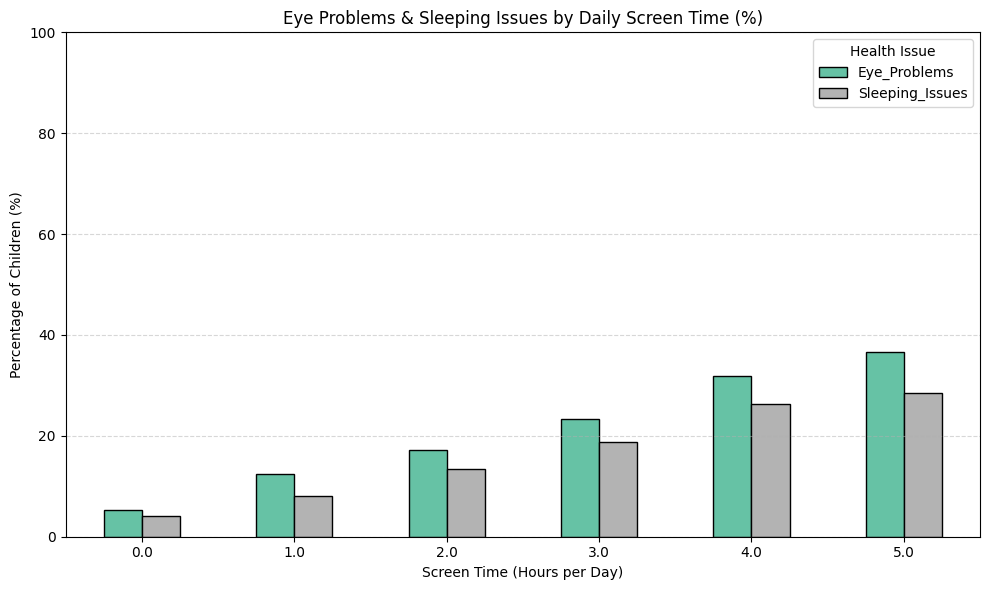

In [50]:


# Focus strictly on the two requested health issues
health_columns = [
    'Eye_Problems',
    'Sleeping_Issues'
]

# 1. Calculate the percentage of 'Yes' for each screen time hour (0 to 5)
screen_summary = df.groupby('Screen_Time_hours_per_day')[health_columns].apply(
    lambda x: (x == 'Yes').mean() * 100
).round(2)

# Display the exact percentage table
print("Percentage (%) of Eye and Sleeping Issues by Daily Screen Time:")
display(screen_summary)

# 2. Plot as a Grouped Bar Chart for these two issues
screen_summary.plot(
    kind='bar',
    figsize=(10, 6),
    colormap='Set2',
    edgecolor='black'
)

plt.title('Eye Problems & Sleeping Issues by Daily Screen Time (%)')
plt.xlabel('Screen Time (Hours per Day)')
plt.ylabel('Percentage of Children (%)')
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(title='Health Issue')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# KEY FINDINGS:

### **1. Summary of Findings**
* **Direct Correlation with Screen Time:** The analysis confirms a strong, steady upward trend between daily screen exposure and the prevalence of both eye problems and sleeping issues among school-age children.
* **Eye Strain Progression:** Children with zero screen time report eye problems at just **5.22%**, but this risk increases drastically as screen time rises, peaking at **36.56%** for children with 5 hours of daily screen time.
* **Sleep Disruption:** Sleeping issues follow a similar pattern, climbing from **4.02%** at 0 hours up to **28.47%** at 5 hours of screen exposure per day.

### **2. Practical Recommendations**
* **Establish Screen Limits:** Caregivers and educators should target keeping recreational screen time below **2 hours per day** to significantly lower the risk of visual and sleep-related health complications.
* **Bedtime Restrictions:** Implementing a strict "no screens" policy at least 1 hour before bedtime can help mitigate the compounding sleeping issues observed in children with higher digital consumption.

# 10)COUNT PLOT(UNIVARIATE ANALYSIS)

# Distribution of Children by Total Number of Co-Occurring Health Issues

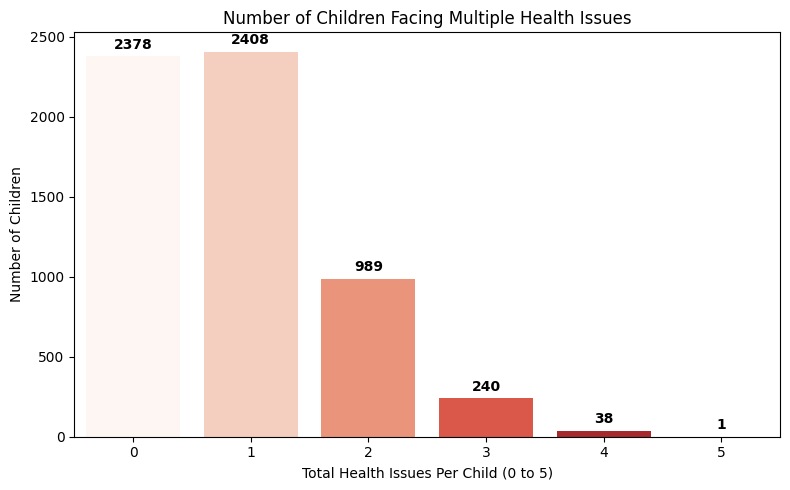

In [51]:


health_columns = [
    'Eye_Problems',
    'Sleeping_Issues',
    'Obesity',
    'Vitamin_D_Deficiency',
    'Chronic_Constipation'
]

# Count how many health issues each child has
df['Total_Health_Issues'] = df[health_columns].apply(lambda row: (row == 'Yes').sum(), axis=1)

# Plot the distribution
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df, x='Total_Health_Issues', palette='Reds', hue='Total_Health_Issues', legend=False)

plt.title('Number of Children Facing Multiple Health Issues')
plt.xlabel('Total Health Issues Per Child (0 to 5)')
plt.ylabel('Number of Children')

# Add count labels on top of the bars
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=10, fontweight='bold',
                xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.show()

# KEY FINDINGS:

The distribution chart analyzing the total number of co-occurring health issues per child reveals the following key insights:

* **Low-Risk Majority:** The vast majority of children experience either **0** (2,378 children) or **1** (2,408 children) health issue, indicating that most children are at low risk.
* **Moderate Risk:** A significant group of **989 children** face **2 concurrent health issues**, showing that overlapping conditions are relatively common.
* **High-Risk Minority:** Severe multi-issue conditions (3 to 5 concurrent health problems) are much rarer, affecting **240 children** at 3 issues down to just **1 child** facing all 5 issues simultaneously.

### **Overall Takeaway**
While many children experience single isolated health problems (like eye strain or vitamin D deficiency), targeted interventions should focus on screening and supporting the high-risk segment of children who suffer from multiple overlapping conditions.

# **Final Summary & Practical Recommendations**

### **1. Summary of Key Findings**
* **Dataset Overview:** After removing 5 duplicate records, dropping 5 invalid age outliers (ages > 17), standardizing text labels, and imputing missing values, the final cleaned dataset consists of **6,054 school-age children (ages 6–17)** across **8 schools** and **16 US cities**.
* **Lifestyle Habits:**
  * **Screen Time:** Students average **2.77 hours/day** (median: **3 hours/day**). Most children spend between **2 and 4 hours** on screens daily, while screen time gradually increases with age (from **2.51 hours** at age 6 to **3.01 hours** at age 17).
  * **Physical Activity:** Students average **1.29 hours/day** (median: **1 hour/day**). Most children exercise **1 to 2 hours/day**, while roughly **1,000 children (16.5%)** report **0 hours** of physical activity.
* **Prevalence of Health Problems:**
  * **Eye Problems:** **22.68%** (1,373 students) — *Most common*
  * **Vitamin D Deficiency:** **22.27%** (1,348 students)
  * **Sleeping Issues:** **17.94%** (1,086 students)
  * **Obesity:** **17.10%** (1,035 students)
  * **Chronic Constipation:** **6.95%** (421 students) — *Least common*
* **Overall Health Burden:** On average, children in this dataset have **0.87 health issues**, with most having **0 or 1 condition**, and a smaller high-risk group experiencing **2 or more concurrent health problems**.

---

### **2. Practical Recommendations**
1. **Healthy Screen-Time Limits (< 2 Hours/Day):** Implement structured daily screen-time limits—especially for older students (ages 14–17) who average ~3 hours/day—and enforce a "no-screens 1 hour before bedtime" rule to protect vision and sleep quality.
2. **Eliminate Zero-Activity Days:** Target the ~1,000 students currently logging **0 hours** of physical activity by introducing mandatory 60-minute daily school physical education or active recess programs.
3. **Outdoor Activity for Vitamin D:** Because **22.27%** of students experience Vitamin D deficiency, schools should schedule physical activities outdoors in natural sunlight rather than indoors.
4. **Proactive School Health Screenings:** Conduct annual vision, BMI, and nutritional screenings across all 8 schools to flag children with multiple risk factors early.